# OPERATION: BLANK MAP — LUCBAN, QUEZON EDITION
### CPE15 Final Examination | Individual Investigator's Notebook

**Student:** Mark Gabriel E. Susim  
**Student ID:** 24-001777  
**Section:** BSCpE-3GF  
**Course:** CPE15 Professional Elective 1: Programming for Data Science  
**Date:** November 20, 2026

**Mission:** Select the three zones most in need of hypothetical mobile digital assistance, verify the sources, defend the analysis, and respond to the sealed operational update.

**Geographic honesty:** The twelve barangay names and approximate reference points are real Lucban, Quezon locations. The 350 m study catchments are synthetic teaching buffers, **not official barangay boundaries**. All household, risk, request, facility, and priority values are simulated for CPE15. Nothing here is an actual LGU needs assessment. Provenance is documented in `data/GEOGRAPHIC_SOURCES.md`: the names and PSGC codes follow the PSA PSGC listing, while the catchments and statistics are teaching simulations.

**Submission:** `CPE15_24-001777_ANALYSIS.ipynb`, `CPE15_24-001777_DECISION.pdf`, and `CPE15_24-001777_SUPPORTING.zip` (containing the final HTML map and processed CSV).

## Workspace and reproducibility

This notebook runs from the supplied `data/` folder only. It does not use the network and does not call GitHub. The examiner should place the original evidence files and the sealed update in `data/` before running it.

Required supplied files:

- `zones.geojson`
- `household_access.csv`
- `risk_index.csv`
- `service_requests.sqlite`
- `facilities.csv`
- `field_notes.txt`
- `sealed_update.txt`

At startup, the notebook checks that each required file exists and compares the original-evidence file hashes to the supplied hashes. It does not modify the original evidence. The current update is a **student-written simulated operational update**, not an official LGU release, and no written instructor permission is included or claimed.

If an official notice is issued, put its exact text in `data/sealed_update.txt` and re-run from the sealed-update cell onward. The results will differ if it names a different facility; regenerate the CSV, map, PDF, and ZIP together.

In [1]:
%matplotlib inline

!pip install -q geopandas folium branca reportlab seaborn

import warnings
from pathlib import Path
import hashlib
import json
import re
import sqlite3
import tempfile
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from branca.colormap import LinearColormap
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

STUDENT_ID = "24-001777"
STUDENT_NAME = "Mark Gabriel E. Susim"
SECTION = "BSCpE-3GF"
COURSE = "CPE15 Professional Elective 1: Programming for Data Science"
MEMO_DATE = "November 20, 2026"

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FIG_DIR = Path("figures")
SUBMISSION_DIR = Path("FINAL_SUBMISSION")
for directory in (DATA_DIR, OUT_DIR, FIG_DIR, SUBMISSION_DIR):
    directory.mkdir(exist_ok=True)

warnings.filterwarnings('ignore')

facilities_url = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/facilities.csv'
household_url = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/household_access.csv'
risk_index_url = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/risk_index.csv'
gjson_url = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/zones.geojson'
service_requests_url = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/service_requests.sqlite'

facilities_df = pd.read_csv(facilities_url)
household_df = pd.read_csv(household_url)
risk_index_df = pd.read_csv(risk_index_url)
gdf = gpd.read_file(gjson_url)
service_requests_path = Path(tempfile.gettempdir()) / 'service_requests.sqlite'
urllib.request.urlretrieve(service_requests_url, service_requests_path)
con = sqlite3.connect(service_requests_path)

facilities_raw = facilities_df
household_raw = household_df
risk_raw = risk_index_df
zones = gdf

print('Loaded Facilities Rows: ', len(facilities_df))
print('Loaded Household Rows: ', len(household_df))
print('Loaded Risk Index Rows: ', len(risk_index_df))
print('Geojson  Rows: ', len(gdf))

ORIGINAL_EVIDENCE_FILES = [
    "zones.geojson",
    "household_access.csv",
    "risk_index.csv",
    "service_requests.sqlite",
    "facilities.csv",
    "field_notes.txt",
]
ORIGINAL_SHA256 = {
    "zones.geojson": "d8b625d73a2f0015a9e0373ba33420f1697493adff6015ad6e5c68ad54b440aa",
    "household_access.csv": "e09371044fc60fd5ccb21c430999e534b7b62364a57c8b38c5df099a362f425d",
    "risk_index.csv": "52d18df23d226642a42c5f0a8eafbf7f7b11ad8dd46e4b39e50dda38b594ee52",
    "service_requests.sqlite": "0bd31d55ee1dbdaea4b3efc253a2a50be8b5d199da3bfc8224f17c9cb8be49ca",
    "facilities.csv": "22036ad913bf628c5e03fdd016da04c7dc17f416d9ab148f95a8c93b941a3a65",
    "field_notes.txt": "70830ac8f3938b3d7246044b88b7fec4bc3353df55b7e9ce3519db1195e46996",
}


def check_original_evidence() -> None:
    """Fail fast if the supplied evidence is not byte-identical to the original."""
    for name in ORIGINAL_EVIDENCE_FILES:
        path = DATA_DIR / name
        assert path.exists(), f"Missing supplied evidence file: {name}"
        actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        expected_hash = ORIGINAL_SHA256[name]
        assert actual_hash == expected_hash, (
            f"Evidence hash mismatch for {name}: expected {expected_hash}, got {actual_hash}"
        )
        print(f"  [PASS] {name} SHA-256 verified")


SEALED_UPDATE_PATH = DATA_DIR / "sealed_update.txt"
FIELD_NOTES_PATH = DATA_DIR / "field_notes.txt"

FIELD_NOTES_URL = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/field_notes.txt'
SEALED_UPDATE_URL = 'https://raw.githubusercontent.com/mesusim-stack/School-Files-/refs/heads/main/Cpe15%20Python%20Activities%20/Finals/data/sealed_update.txt'


def _download_to_temp(url: str, filename: str) -> Path:
    target = Path(tempfile.gettempdir()) / filename
    urllib.request.urlretrieve(url, target)
    return target


if FIELD_NOTES_PATH.exists():
    FIELD_NOTES_TEXT = FIELD_NOTES_PATH.read_text(encoding="utf-8")
else:
    FIELD_NOTES_PATH = _download_to_temp(FIELD_NOTES_URL, "field_notes.txt")
    FIELD_NOTES_TEXT = FIELD_NOTES_PATH.read_text(encoding="utf-8")

if SEALED_UPDATE_PATH.exists():
    UPDATE_TEXT = SEALED_UPDATE_PATH.read_text(encoding="utf-8").strip()
else:
    SEALED_UPDATE_PATH = _download_to_temp(SEALED_UPDATE_URL, "sealed_update.txt")
    UPDATE_TEXT = SEALED_UPDATE_PATH.read_text(encoding="utf-8").strip()

print("Library versions")
for name, module in [
    ("pandas", pd),
    ("numpy", np),
    ("geopandas", gpd),
    ("folium", folium),
    ("matplotlib", matplotlib),
]:
    print(f"  {name}: {module.__version__}")
print("Evidence ready:")
for name in ORIGINAL_EVIDENCE_FILES:
    print(f"  {name}: data/")
print("  sealed_update.txt: data/ or student source URL")
print("  field_notes.txt: data/ or student source URL")
print("Data sources: local evidence preferred; student raw-file URLs as fallback.")


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Haacha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Loaded Facilities Rows:  5
Loaded Household Rows:  13
Loaded Risk Index Rows:  13
Geojson  Rows:  12
Library versions
  pandas: 3.1.1
  numpy: 2.4.6
  geopandas: 1.2.0
  folium: 1.0.0
  matplotlib: 3.11.2
Evidence ready:
  zones.geojson: data/
  household_access.csv: data/
  risk_index.csv: data/
  service_requests.sqlite: data/
  facilities.csv: data/
  field_notes.txt: data/
  sealed_update.txt: data/ or student source URL
  field_notes.txt: data/ or student source URL
Data sources: local evidence preferred; student raw-file URLs as fallback.


## 1. Evidence audit | What is trustworthy?

The source package is deliberately imperfect. I inspect the raw tables first, then use **only** the statements marked `VERIFIED` in `field_notes.txt` to repair records. The original files are never overwritten.

In [2]:
zones = gdf
household_raw = household_df
risk_raw = risk_index_df
facilities_raw = facilities_df
notes = FIELD_NOTES_TEXT

print("Raw evidence shapes")
print("  zones:", zones.shape, "| CRS:", zones.crs)
print("  household:", household_raw.shape)
print("  risk:", risk_raw.shape)
print("  facilities:", facilities_raw.shape)

print("\nHousehold access (raw)")
display(household_raw)
print("\nRisk index (raw)")
display(risk_raw)
print("\nFacilities (raw)")
display(facilities_raw)

Raw evidence shapes
  zones: (12, 8) | CRS: EPSG:4326
  household: (13, 3)
  risk: (13, 2)
  facilities: (5, 5)

Household access (raw)


,zone_code,total_households,households_with_access
0,A01,850,520.0
1,A02,700,238.0
2,A-03,500,228.0
3,A04,350,260.0
4,A05,460,325.0
5,A06,820,NaN
6,A07,1100,400.0
7,A07,1100,400.0
8,A08,650,150.0
9,A09,500,220.0



Risk index (raw)


,zone_code,risk_score
0,A01,40
1,A02,80
2,A03,66
3,A04,25
4,A05,40
5,A06,48
6,A07,55
7,A08,77
8,A09,72
9,A10,24



Facilities (raw)


,facility_id,facility_name,longitude,latitude,status
0,F01,Scenario Assistance Hub — Kalangay,121.552,14.1570,operational
1,F02,Scenario Assistance Hub — Kilib,121.570,14.1275,operational
2,F03,Scenario Assistance Hub — Nagsinamo,121.602,14.1100,operational
3,F04,Scenario Assistance Hub — Tiawe,121.595,14.0817,operational
4,F05,Scenario Assistance Hub — Kalyaat,121.530,14.1427,operational


### Native-Python parsing of the verified field notes

The corrections are parsed with regular expressions, not hardcoded constants. This makes the audit traceable to the bulletin and avoids silently inventing replacements.

In [3]:
def normalize_zone(value: object) -> str:
    """Canonicalize zone identifiers: A-03 -> A03, whitespace stripped."""
    return str(value).strip().upper().replace("-", "")


verified_lines = [line.strip() for line in notes.splitlines() if "VERIFIED" in line]
print("Verified field-note statements")
for line in verified_lines:
    print(" ", line)

corrections: dict[str, dict] = {}
for line in verified_lines:
    m = re.search(
        r"zone code\s+(A-\d+)\s+is an alternate entry for\s+(A\d+)\s+in ALL source files",
        line,
        flags=re.IGNORECASE,
    )
    if m:
        corrections["alias"] = {
            "alias": m.group(1).upper(),
            "canonical": m.group(2).upper(),
            "source": line,
        }
        continue

    m = re.search(
        r"missing households_with_access value for\s+(A\d+)\s+is\s+(\d+)",
        line,
        flags=re.IGNORECASE,
    )
    if m:
        corrections["missing_access"] = {
            "zone": m.group(1).upper(),
            "value": int(m.group(2)),
            "source": line,
        }
        continue

    m = re.search(
        r"erroneous households_with_access value\s+(\d+)\s+for\s+(A\d+)\s+is superseded by\s+(\d+)",
        line,
        flags=re.IGNORECASE,
    )
    if m:
        corrections["erroneous_access"] = {
            "old": int(m.group(1)),
            "zone": m.group(2).upper(),
            "new": int(m.group(3)),
            "source": line,
        }
        continue

    m = re.search(
        r"For\s+(A\d+),\s+risk_score\s+(\d+)\s+is current;\s+risk_score\s+(\d+)\s+is an obsolete duplicate",
        line,
        flags=re.IGNORECASE,
    )
    if m:
        corrections["risk_duplicate"] = {
            "zone": m.group(1).upper(),
            "current": int(m.group(2)),
            "obsolete": int(m.group(3)),
            "source": line,
        }
        continue

required_keys = {"alias", "missing_access", "erroneous_access", "risk_duplicate"}
assert required_keys.issubset(corrections), f"Unparsed field note(s): {required_keys - set(corrections)}"
print("\nParsed corrections")
for key, value in corrections.items():
    print(f"  {key}: {value}")

print("\nSQLite request status counts")
# Guard: ensure the requests table exists (protects against a bad download).
table_names = [row[0] for row in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()]
assert "requests" in table_names, f"Missing 'requests' table in downloaded SQLite. Downloaded file may be corrupt."
status_counts = pd.read_sql_query(
    "SELECT status, COUNT(*) AS n FROM requests GROUP BY status ORDER BY status", con
)
duplicate_request_ids = pd.read_sql_query(
    "SELECT request_id, COUNT(*) AS n FROM requests GROUP BY request_id HAVING COUNT(*) > 1 ORDER BY request_id",
    con,
)
print("Duplicate request IDs (excluded by COUNT(DISTINCT))")

Verified field-note statements
  Only the statements marked VERIFIED below authorize record corrections.
  FN-01 VERIFIED: The zone code A-03 is an alternate entry for A03 in ALL source files.
  FN-02 VERIFIED: The missing households_with_access value for A06 is 350.
  FN-03 VERIFIED: The erroneous households_with_access value 1220 for A11 is superseded by 220.
  FN-04 VERIFIED: For A09, risk_score 72 is current; risk_score 96 is an obsolete duplicate entry.

Parsed corrections
  alias: {'alias': 'A-03', 'canonical': 'A03', 'source': 'FN-01 VERIFIED: The zone code A-03 is an alternate entry for A03 in ALL source files.'}
  missing_access: {'zone': 'A06', 'value': 350, 'source': 'FN-02 VERIFIED: The missing households_with_access value for A06 is 350.'}
  erroneous_access: {'old': 1220, 'zone': 'A11', 'new': 220, 'source': 'FN-03 VERIFIED: The erroneous households_with_access value 1220 for A11 is superseded by 220.'}
  risk_duplicate: {'zone': 'A09', 'current': 72, 'obsolete': 96, 'sou

## 2. Reconstruction | One validated row per zone

Repairs applied: normalize the `A-03` alias, fill the verified A06 access value, replace the impossible A11 value, drop the identical A07 duplicate, keep the current A09 risk score, and count **distinct** eligible request IDs only.

In [4]:
# Household access
hh = household_raw.copy()
hh["zone_id"] = hh["zone_code"].map(normalize_zone)
hh["total_households"] = pd.to_numeric(hh["total_households"], errors="coerce")
hh["households_with_access"] = pd.to_numeric(hh["households_with_access"], errors="coerce")
a07_duplicate_verified = False
duplicate_household_rows = hh[hh.duplicated("zone_id", keep=False)].copy()
if len(duplicate_household_rows):
    for duplicate_zone, duplicate_group in duplicate_household_rows.groupby("zone_id"):
        assert (
            duplicate_group.drop(columns="zone_id").nunique(dropna=False).le(1).all().all()
        ), f"Duplicate household rows for {duplicate_zone} are not identical."
    if "A07" in duplicate_household_rows["zone_id"].unique():
        a07_rows = duplicate_household_rows[duplicate_household_rows["zone_id"] == "A07"]
        assert len(a07_rows) == 2, "Expected exactly two A07 household rows for the duplicate check."
        assert a07_rows.drop(columns="zone_id").nunique(dropna=False).eq(1).all().all(), "A07 duplicate rows are not identical."
        a07_duplicate_verified = True
        print("A07 duplicate row check: PASS; both rows are identical.")
    print(
        "Duplicate household rows confirmed identical for:",
        duplicate_household_rows["zone_id"].unique().tolist(),
    )
hh = hh.drop_duplicates("zone_id", keep="first").copy()

missing = corrections["missing_access"]
hh.loc[hh["zone_id"] == missing["zone"], "households_with_access"] = missing["value"]

err = corrections["erroneous_access"]
err_mask = (hh["zone_id"] == err["zone"]) & np.isclose(
    hh["households_with_access"], err["old"], equal_nan=False
)
hh.loc[err_mask, "households_with_access"] = err["new"]

assert hh["households_with_access"].notna().all(), "Unresolved missing access value."
assert (hh["households_with_access"] <= hh["total_households"]).all(), "Access exceeds total households."
assert hh["zone_id"].is_unique, "Household table is not one row per zone."

# Risk
risk = risk_raw.copy()
risk["zone_id"] = risk["zone_code"].map(normalize_zone)
risk["risk_score"] = pd.to_numeric(risk["risk_score"], errors="coerce")
rd = corrections["risk_duplicate"]
risk = risk[
    ~((risk["zone_id"] == rd["zone"]) & np.isclose(risk["risk_score"], rd["obsolete"]))
].copy()
risk = risk.drop_duplicates("zone_id", keep="first")
assert risk["zone_id"].is_unique, "Risk table is not one row per zone."
assert risk["risk_score"].between(0, 100).all(), "Risk score outside 0-100."

# Eligible requests, with alias normalization inside SQL
sql = """
SELECT
    CASE
        WHEN UPPER(REPLACE(TRIM(zone_code), '-', '')) = 'A03' THEN 'A03'
        ELSE UPPER(REPLACE(TRIM(zone_code), '-', ''))
    END AS zone_id,
    COUNT(DISTINCT request_id) AS valid_requests
FROM requests
WHERE LOWER(TRIM(status)) IN ('verified', 'open')
GROUP BY 1
ORDER BY 1
"""
req = pd.read_sql_query(sql, con)
con.close()
req = (
    req.set_index("zone_id")
    .reindex(zones["zone_id"].str.strip().str.upper())
    .fillna(0)
    .astype(int)
    .rename_axis("zone_id")
    .reset_index()
)
assert len(req) == 12, "Request table does not cover all 12 zones."

# Integrate
df = zones.copy()
df["zone_id"] = df["zone_id"].str.strip().str.upper()
df = df.merge(
    hh[["zone_id", "total_households", "households_with_access"]], on="zone_id", how="left"
)
df = df.merge(risk[["zone_id", "risk_score"]], on="zone_id", how="left")
df = df.merge(req, on="zone_id", how="left")

assert len(df) == 12 and df["zone_id"].is_unique, "Integrated table is not one row per zone."
assert df[["total_households", "households_with_access", "risk_score", "valid_requests"]].notna().all().all()

print("Validated analysis table (inputs)")
display(
    df[
        [
            "zone_id",
            "zone_name",
            "total_households",
            "households_with_access",
            "risk_score",
            "valid_requests",
        ]
    ]
)

print("Data dictionary")
data_dictionary = pd.DataFrame(
    [
        ("zone_id", "Canonical zone identifier (A01-A12)"),
        ("zone_name", "Real barangay name used as a study-catchment label"),
        ("total_households", "Validated household total (simulated)"),
        ("households_with_access", "Validated households with digital access (simulated)"),
        ("risk_score", "Validated community risk score, 0-100 (simulated)"),
        ("valid_requests", "Distinct request_id with status verified/open"),
        ("service_gap", "100 * (1 - access / total)"),
        ("distance_km", "Projected centroid to nearest operational facility, km"),
        ("distance_score", "100 * distance / maximum zone distance in the scenario"),
        ("demand_score", "100 * valid_requests / maximum zone valid requests"),
        ("priority", "0.45*gap + 0.25*risk + 0.20*distance_score + 0.10*demand_score"),
    ],
    columns=["field", "definition"],
)
display(data_dictionary)

A07 duplicate row check: PASS; both rows are identical.
Duplicate household rows confirmed identical for: ['A07']
Validated analysis table (inputs)


,zone_id,zone_name,total_households,households_with_access,risk_score,valid_requests
0,A01,Abang,850,520.0,40,23
1,A02,Aliliw,700,238.0,80,29
2,A03,Atulinao,500,228.0,66,36
3,A04,Kalangay,350,260.0,25,14
4,A05,Kalyaat,460,325.0,40,17
5,A06,Kilib,820,350.0,48,32
6,A07,Kulapi,1100,400.0,55,35
7,A08,Malupak,650,150.0,77,28
8,A09,Nagsinamo,500,220.0,72,40
9,A10,Nalunao,410,300.0,24,11


Data dictionary


,field,definition
0,zone_id,Canonical zone identifier (A01-A12)
1,zone_name,Real barangay name used as a study-catchment l...
2,total_households,Validated household total (simulated)
3,households_with_access,Validated households with digital access (simu...
4,risk_score,"Validated community risk score, 0-100 (simulated)"
5,valid_requests,Distinct request_id with status verified/open
6,service_gap,100 * (1 - access / total)
7,distance_km,Projected centroid to nearest operational faci...
8,distance_score,100 * distance / maximum zone distance in the ...
9,demand_score,100 * valid_requests / maximum zone valid requ...


### Correction log

Every repair is tied to its source. Unresolved uncertainty is stated rather than hidden.

In [5]:
correction_log = pd.DataFrame(
    [
        {
            "issue": "Zone-code alias A-03 appears alongside A03",
            "evidence": corrections["alias"]["source"],
            "action": "Normalized A-03 to A03 in the household table and SQL request aggregation; risk_index.csv already used A03, so no risk-row change was needed.",
            "affected_records": "A03 household and request rows; risk table already used A03",
            "impact": "Prevented a false missing zone and a dropped join",
            "residual_uncertainty": "FN-01 verifies the alias; assumes no separate A-03 zone exists. The risk table already used A03, so no risk-row correction was needed.",
        },
        {
            "issue": "Missing households_with_access for A06",
            "evidence": corrections["missing_access"]["source"],
            "action": "Applied verified value 350",
            "affected_records": "A06",
            "impact": "A06 service gap is computable instead of missing",
            "residual_uncertainty": "FN-02 supplies 350; no independent household listing is available to cross-check.",
        },
        {
            "issue": "Impossible access count 1220 for A11 (total 780)",
            "evidence": corrections["erroneous_access"]["source"],
            "action": "Replaced 1220 with verified 220",
            "affected_records": "A11",
            "impact": "Corrected an impossible 156% access rate",
            "residual_uncertainty": "FN-03 supersedes 1220 with 220; the original entry is treated as a data-entry error.",
        },
        {
            "issue": "Duplicate household row for A07",
            "evidence": "household_access.csv: two identical A07 rows",
            "action": "Kept one row after asserting the duplicate rows are identical",
            "affected_records": "A07",
            "impact": "Prevented double counting of households",
            "residual_uncertainty": "The duplicate rows are identical, so dropping one loses no information.",
        },
        {
            "issue": "Obsolete duplicate risk entry A09 = 96",
            "evidence": corrections["risk_duplicate"]["source"],
            "action": "Kept current A09 risk = 72 and removed 96",
            "affected_records": "A09",
            "impact": "Prevented an inflated risk component",
            "residual_uncertainty": "FN-04 identifies 96 as obsolete; 72 is treated as current.",
        },
        {
            "issue": "Duplicate request IDs",
            "evidence": "service_requests.sqlite: repeated request_id values",
            "action": "Counted COUNT(DISTINCT request_id) only",
            "affected_records": "A01, A03, A06 duplicates",
            "impact": "Prevented demand inflation",
            "residual_uncertainty": "COUNT(DISTINCT) assumes repeated IDs are duplicate submissions, not separate requests.",
        },
        {
            "issue": "Ineligible request statuses",
            "evidence": "service_requests.sqlite status counts",
            "action": "Filtered to verified/open only",
            "affected_records": "cancelled and invalid rows",
            "impact": "Demand reflects active requests only",
            "residual_uncertainty": "Only verified/open are treated as active demand, per the field-note rule.",
        },
    ]
)
display(correction_log)
residual_values = correction_log["residual_uncertainty"].astype(str).str.strip()
assert residual_values.notna().all(), "Correction log is missing residual uncertainty."
assert (residual_values != "").all(), "Correction log has empty residual uncertainty."
print(f"Correction residual uncertainty populated: {len(residual_values)} of {len(residual_values)} entries.")

,issue,evidence,action,affected_records,impact,residual_uncertainty
0,Zone-code alias A-03 appears alongside A03,FN-01 VERIFIED: The zone code A-03 is an alter...,Normalized A-03 to A03 in the household table ...,A03 household and request rows; risk table alr...,Prevented a false missing zone and a dropped join,FN-01 verifies the alias; assumes no separate ...
1,Missing households_with_access for A06,FN-02 VERIFIED: The missing households_with_ac...,Applied verified value 350,A06,A06 service gap is computable instead of missing,FN-02 supplies 350; no independent household l...
2,Impossible access count 1220 for A11 (total 780),FN-03 VERIFIED: The erroneous households_with_...,Replaced 1220 with verified 220,A11,Corrected an impossible 156% access rate,FN-03 supersedes 1220 with 220; the original e...
3,Duplicate household row for A07,household_access.csv: two identical A07 rows,Kept one row after asserting the duplicate row...,A07,Prevented double counting of households,"The duplicate rows are identical, so dropping ..."
4,Obsolete duplicate risk entry A09 = 96,"FN-04 VERIFIED: For A09, risk_score 72 is curr...",Kept current A09 risk = 72 and removed 96,A09,Prevented an inflated risk component,FN-04 identifies 96 as obsolete; 72 is treated...
5,Duplicate request IDs,service_requests.sqlite: repeated request_id v...,Counted COUNT(DISTINCT request_id) only,"A01, A03, A06 duplicates",Prevented demand inflation,COUNT(DISTINCT) assumes repeated IDs are dupli...
6,Ineligible request statuses,service_requests.sqlite status counts,Filtered to verified/open only,cancelled and invalid rows,Demand reflects active requests only,Only verified/open are treated as active deman...


Correction residual uncertainty populated: 7 of 7 entries.


## 3. Spatial analysis and original ranking

The GeoJSON is in EPSG:4326. Distance must not be measured in degrees, so I reproject to **EPSG:32651 (UTM Zone 51N)**, which is appropriate for Lucban (approximately 121.5°E, 14.1°N). I compute polygon centroids in that projected CRS and measure straight-line centroid-to-facility distances. These are **not road travel distances**.

In [6]:
assert df.crs is not None, "zones.geojson has no CRS."
zones_proj = df.to_crs(32651)  # UTM Zone 51N
centroids_proj = zones_proj.geometry.centroid
centroids_wgs84 = centroids_proj.to_crs(4326)
df["centroid_lon"] = centroids_wgs84.x.values
df["centroid_lat"] = centroids_wgs84.y.values
df["centroid_x_m"] = centroids_proj.x.values
df["centroid_y_m"] = centroids_proj.y.values

fac = facilities_raw.copy()
fac["longitude"] = pd.to_numeric(fac["longitude"], errors="coerce")
fac["latitude"] = pd.to_numeric(fac["latitude"], errors="coerce")
fac["status"] = fac["status"].str.strip().str.lower()
fac_gdf = gpd.GeoDataFrame(
    fac, geometry=gpd.points_from_xy(fac["longitude"], fac["latitude"]), crs=4326
).to_crs(32651)

operational = fac_gdf[fac_gdf["status"] == "operational"].copy()
assert len(operational) > 0, "No operational facility in the original scenario."


def nearest_facility(row, facilities: gpd.GeoDataFrame) -> pd.Series:
    distances = facilities.geometry.distance(row.geometry.centroid)
    idx = distances.idxmin()
    return pd.Series(
        {
            "nearest_facility_id": facilities.loc[idx, "facility_id"],
            "nearest_facility_name": facilities.loc[idx, "facility_name"],
            "distance_km": distances.loc[idx] / 1000.0,
        }
    )


nearest = zones_proj.apply(lambda row: nearest_facility(row, operational), axis=1)
for col in nearest.columns:
    df[col] = nearest[col].values

max_distance = df["distance_km"].max()
max_requests = df["valid_requests"].max()
df["service_gap"] = 100.0 * (1.0 - df["households_with_access"] / df["total_households"])
df["distance_score"] = (
    100.0 * df["distance_km"] / max_distance if max_distance > 0 else 0.0
)
df["demand_score"] = (
    100.0 * df["valid_requests"] / max_requests if max_requests > 0 else 0.0
)
df["priority"] = (
    0.45 * df["service_gap"]
    + 0.25 * df["risk_score"]
    + 0.20 * df["distance_score"]
    + 0.10 * df["demand_score"]
)

df = df.sort_values(["priority", "zone_id"], ascending=[False, True]).reset_index(drop=True)
df["rank"] = np.arange(1, len(df) + 1)

df["original_priority"] = df["priority"]
df["original_rank"] = df["rank"]
df["original_nearest_facility_id"] = df["nearest_facility_id"]
df["original_nearest_facility_name"] = df["nearest_facility_name"]
df["original_distance_km"] = df["distance_km"]
df["original_distance_score"] = df["distance_score"]

print("Original ranking (descending priority; exact ties by ascending zone_id)")
display(
    df[
        [
            "rank",
            "zone_id",
            "zone_name",
            "service_gap",
            "risk_score",
            "distance_km",
            "distance_score",
            "valid_requests",
            "demand_score",
            "priority",
            "nearest_facility_id",
        ]
    ].round(3)
)

original_top3 = df.head(3)[["zone_id", "zone_name", "priority", "rank"]].copy()
print("Original top three")
display(original_top3.round(2))

Original ranking (descending priority; exact ties by ascending zone_id)

,rank,zone_id,zone_name,service_gap,risk_score,distance_km,distance_score,valid_requests,demand_score,priority,nearest_facility_id
0,1,A08,Malupak,76.923,77,1.196,50.614,28,70.0,70.988,F03
1,2,A02,Aliliw,66.000,80,1.349,57.070,29,72.5,68.364,F02
2,3,A07,Kulapi,63.636,55,1.541,65.209,35,87.5,64.178,F02
3,4,A03,Atulinao,54.400,66,1.589,67.225,36,90.0,63.425,F03
4,5,A11,Tiawe,71.795,72,0.124,5.232,32,80.0,59.354,F04
5,6,A09,Nagsinamo,56.000,72,0.510,21.573,40,100.0,57.515,F03
6,7,A12,Tinamnan,37.500,40,2.364,100.000,25,62.5,53.125,F04
7,8,A01,Abang,38.824,40,2.032,85.962,23,57.5,50.413,F02
8,9,A06,Kilib,57.317,48,0.446,18.860,32,80.0,49.565,F02
9,10,A10,Nalunao,26.829,24,1.796,75.984,11,27.5,36.020,F01


Original top three


,zone_id,zone_name,priority,rank
0,A08,Malupak,70.99,1
1,A02,Aliliw,68.36,2
2,A07,Kulapi,64.18,3


## 4. Intelligence board | Two analytical charts

**Chart 1** answers: *which zones rank highest under the supplied policy?*  
**Chart 2** answers a different question: *do the highest-gap zones also carry the highest eligible demand?*

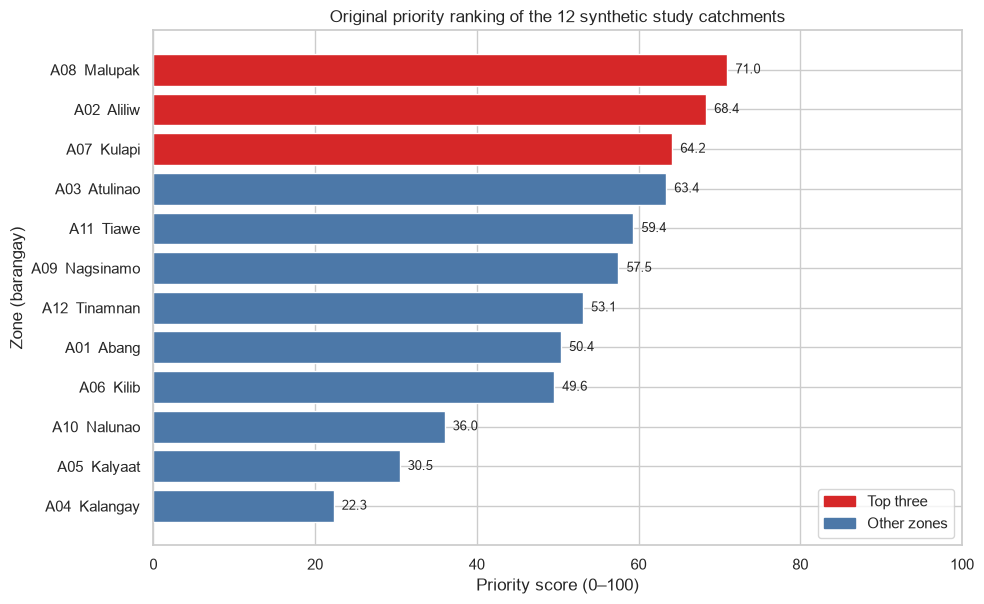

In [7]:
sns.set_theme(style="whitegrid", context="notebook")

plot_df = df.sort_values("priority", ascending=True)
colors = ["#d62728" if r <= 3 else "#4c78a8" for r in plot_df["rank"]]
fig1, ax1 = plt.subplots(figsize=(10, 6.2))
bars = ax1.barh(
    plot_df["zone_id"] + "  " + plot_df["zone_name"],
    plot_df["priority"],
    color=colors,
    edgecolor="white",
)
for bar, value in zip(bars, plot_df["priority"]):
    ax1.text(value + 1.0, bar.get_y() + bar.get_height() / 2, f"{value:.1f}", va="center", fontsize=9)
ax1.set_xlim(0, 100)
ax1.set_xlabel("Priority score (0–100)")
ax1.set_ylabel("Zone (barangay)")
ax1.set_title("Original priority ranking of the 12 synthetic study catchments")
ax1.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="#d62728", label="Top three"),
        plt.Rectangle((0, 0), 1, 1, color="#4c78a8", label="Other zones"),
    ],
    loc="lower right",
    frameon=True,
)
fig1.tight_layout()
fig1.savefig(FIG_DIR / "chart1_priority_ranking.png", dpi=160)
plt.show()

**Interpretation.** A08 Malupak leads because it combines the largest household service gap (76.9%) with a high risk score (77). A02 Aliliw is second on the strength of the highest risk score (80) and a 66.0% gap. A07 Kulapi is third with a 63.6% gap and the second-highest eligible demand (35 distinct requests). A03 Atulinao is a close fourth (63.4 vs 64.2), so the top-three boundary is sensitive to small corrections.

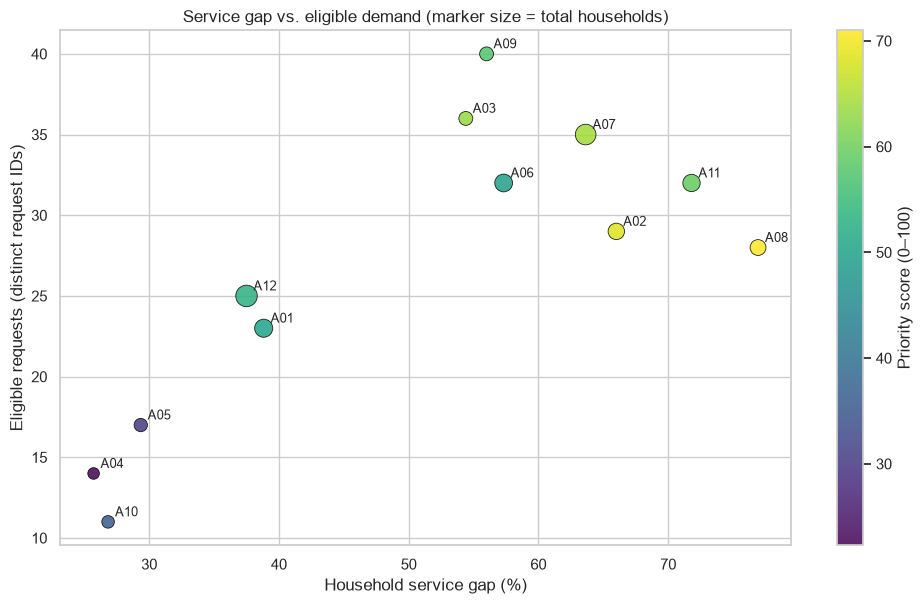

In [8]:
fig2, ax2 = plt.subplots(figsize=(10, 6.2))
scatter = ax2.scatter(
    df["service_gap"],
    df["valid_requests"],
    s=df["total_households"] / 5.0,
    c=df["priority"],
    cmap="viridis",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.85,
)
for _, row in df.iterrows():
    ax2.annotate(
        row["zone_id"],
        (row["service_gap"], row["valid_requests"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=9,
    )
cbar = fig2.colorbar(scatter, ax=ax2)
cbar.set_label("Priority score (0–100)")
ax2.set_xlabel("Household service gap (%)")
ax2.set_ylabel("Eligible requests (distinct request IDs)")
ax2.set_title("Service gap vs. eligible demand (marker size = total households)")
fig2.tight_layout()
fig2.savefig(FIG_DIR / "chart2_gap_vs_demand.png", dpi=160)
plt.show()

**Interpretation.** The relationship is not one-dimensional. A11 Tiawe has a high service gap (71.8%) but sits close to an operational facility, while A12 Tinamnan has a much lower gap (37.5%) but the greatest distance to an operational facility. A08 and A07 combine relatively high gap and demand, which is why they remain near the top. The chart shows why a single indicator would produce a different recommendation.

## 5. Interactive intelligence map

The map is a standalone HTML file. It uses synthetic catchment polygons, real barangay labels, fictional facility markers, layer controls, popups, tooltips, a legend, and an explicit disclaimer. The original-scenario map is built first; it is replaced by the revised map after the student-written simulated update.

In [9]:
def build_map(data, facilities, scenario_label, affected_ids, output_path):
    """Build and save a standalone Folium map for one scenario."""
    map_df = data.copy()
    if map_df.crs is None:
        map_df = map_df.set_crs(4326)
    map_df = map_df.to_crs(4326)
    geojson_data = json.loads(map_df.to_json())

    vmin = float(map_df["map_priority"].min())
    vmax = float(map_df["map_priority"].max())
    if vmax == vmin:
        vmax = vmin + 1.0
    cmap = LinearColormap(
        ["#2c7bb6", "#ffffbf", "#d7191c"],
        vmin=vmin,
        vmax=vmax,
        caption="Priority score (0–100)",
    )

    def style_function(feature):
        value = feature["properties"]["map_priority"]
        return {
            "fillColor": cmap(value),
            "color": "#333333",
            "weight": 1.0,
            "fillOpacity": 0.68,
        }

    m = folium.Map(
        location=[float(map_df["centroid_lat"].mean()), float(map_df["centroid_lon"].mean())],
        zoom_start=11,
        tiles=None,
        control_scale=True,
    )

    # Esri basemaps are used instead of OpenStreetMap because OSM's public tile
    # server can return an "Access blocked" tile when a local HTML file is opened
    # directly from disk. Esri's ArcGIS Online basemaps work from file:// URLs.
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr=(
            "Tiles &copy; Esri &mdash; Source: Esri, DeLorme, NAVTEQ, USGS, "
            "Intermap, iPC, NRCAN, Esri Japan, METI, Esri China (Hong Kong), "
            "Esri (Thailand), TomTom, 2012"
        ),
        name="Street map (Esri)",
        overlay=False,
        control=True,
        show=True,
    ).add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr=(
            "Tiles &copy; Esri &mdash; Source: Esri, Maxar, Earthstar Geographics, "
            "and the GIS User Community"
        ),
        name="Satellite imagery (Esri)",
        overlay=False,
        control=True,
        show=False,
    ).add_to(m)

    zones_layer = folium.FeatureGroup(name="Synthetic study catchments", show=True)
    folium.GeoJson(
        geojson_data,
        style_function=style_function,
        highlight_function=lambda feature: {"weight": 3, "color": "#111111", "fillOpacity": 0.85},
        tooltip=folium.GeoJsonTooltip(
            fields=[
                "zone_id",
                "zone_name",
                "map_priority",
                "map_rank",
                "service_gap",
                "risk_score",
                "valid_requests",
                "map_distance_km",
                "map_nearest_facility_id",
            ],
            aliases=[
                "Zone",
                "Barangay",
                "Priority",
                "Rank",
                "Service gap (%)",
                "Risk",
                "Eligible requests",
                "Distance to facility (km)",
                "Nearest facility",
            ],
            localize=True,
            sticky=False,
        ),
        popup=folium.GeoJsonPopup(
            fields=[
                "zone_id",
                "zone_name",
                "total_households",
                "households_with_access",
                "service_gap",
                "risk_score",
                "valid_requests",
                "map_distance_km",
                "map_distance_score",
                "demand_score",
                "map_priority",
                "map_rank",
                "map_nearest_facility_id",
                "map_nearest_facility_name",
            ],
            aliases=[
                "Zone",
                "Barangay",
                "Total households",
                "Households with access",
                "Service gap (%)",
                "Risk score",
                "Eligible requests",
                "Distance (km)",
                "Distance score",
                "Demand score",
                "Priority score",
                "Rank",
                "Nearest facility",
                "Facility name",
            ],
            localize=True,
        ),
    ).add_to(zones_layer)
    zones_layer.add_to(m)

    labels_layer = folium.FeatureGroup(name="Zone labels", show=True)
    for _, row in map_df.iterrows():
        folium.Marker(
            location=[row["centroid_lat"], row["centroid_lon"]],
            icon=folium.DivIcon(
                html=(
                    '<div style="font-size:10px;font-weight:700;color:#111;'
                    'text-shadow:0 0 3px #fff,0 0 3px #fff;white-space:nowrap;">'
                    f'{row["zone_id"]} {row["zone_name"]}</div>'
                ),
                icon_size=(0, 0),
                icon_anchor=(0, 0),
            ),
        ).add_to(labels_layer)
    labels_layer.add_to(m)

    facilities_layer = folium.FeatureGroup(name="Fictional assistance facilities", show=True)
    fac_map = facilities.copy()
    if fac_map.crs is None:
        fac_map = fac_map.set_crs(4326)
    fac_map = fac_map.to_crs(4326)
    for _, row in fac_map.iterrows():
        status = str(row["status"]).lower()
        color = "green" if status == "operational" else "red"
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            tooltip=f"{row['facility_id']}: {row['facility_name']} ({status})",
            popup=folium.Popup(
                f"<b>{row['facility_id']} — {row['facility_name']}</b><br>"
                f"Status: <b>{status}</b><br>"
                "<i>Fictional assistance hub; not an actual LGU facility.</i>",
                max_width=320,
            ),
            icon=folium.Icon(color=color, icon="info-sign"),
        ).add_to(facilities_layer)
    facilities_layer.add_to(m)

    if affected_ids:
        affected_layer = folium.FeatureGroup(name="Facility status changed by update", show=True)
        for _, row in fac_map[fac_map["facility_id"].isin(affected_ids)].iterrows():
            folium.CircleMarker(
                location=[row.geometry.y, row.geometry.x],
                radius=16,
                color="#ff7f0e",
                weight=3,
                fill=False,
                tooltip=f"{row['facility_id']} — {row['facility_name']} — status changed by update",
            ).add_to(affected_layer)
        affected_layer.add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)

    affected_note = ""
    if affected_ids:
        affected_note = (
            "<br><span style='color:#ff7f0e;'>&#9711;</span> "
            f"Facility status changed by update ({', '.join(affected_ids)})"
        )
    legend_html = f"""
    <div style="position: fixed; bottom: 28px; left: 28px; z-index: 9999;
                background: white; padding: 10px 12px; border: 1px solid #444;
                border-radius: 6px; font-size: 12px; line-height: 1.45; max-width: 350px;
                box-shadow: 0 1px 4px rgba(0,0,0,.25);">
      <b>Priority score</b><br>
      <div style="height: 12px; width: 220px; border: 1px solid #999;
                  background: linear-gradient(to right, #2c7bb6, #ffffbf, #d7191c);"></div>
      <div style="display: flex; justify-content: space-between; width: 220px;">
        <span>{vmin:.1f}</span><span>{vmax:.1f}</span>
      </div>
      <b>Facilities</b><br>
      <span style="color: green;">&#9679;</span> Operational &nbsp;
      <span style="color: red;">&#9679;</span> Non-operational
      {affected_note}<br>
      <i>Synthetic 350 m study catchments around approximate reference points.
      These are not official barangay boundaries. All statistics and facilities
      are simulated for CPE15 teaching purposes. The operational update is a
      student-written simulation, not an official LGU release; no written
      instructor permission is included or claimed.</i>
    </div>
    """
    m.get_root().html.add_child(folium.Element(legend_html))

    title_html = f"""
    <div style="position: fixed; top: 12px; left: 50px; z-index: 9999;
                background: white; padding: 10px 14px; border: 1px solid #444;
                border-radius: 6px; font-size: 14px; line-height: 1.35;
                box-shadow: 0 1px 4px rgba(0,0,0,.25);">
      <b>Operation Blank Map — Lucban, Quezon</b><br>
      Priority deployment screening: {scenario_label}<br>
      <span style="font-size: 11px;">Synthetic catchments; not official barangay boundaries.</span>
    </div>
    """
    m.get_root().html.add_child(folium.Element(title_html))

    bounds = map_df.total_bounds
    m.fit_bounds([[bounds[1], bounds[0]], [bounds[3], bounds[2]]])
    m.save(str(output_path))
    return m


original_map_data = df.copy()
original_map_data["map_priority"] = original_map_data["original_priority"]
original_map_data["map_rank"] = original_map_data["original_rank"]
original_map_data["map_distance_km"] = original_map_data["original_distance_km"]
original_map_data["map_distance_score"] = original_map_data["original_distance_score"]
original_map_data["map_nearest_facility_id"] = original_map_data["original_nearest_facility_id"]
original_map_data["map_nearest_facility_name"] = original_map_data["original_nearest_facility_name"]

original_map_path = OUT_DIR / f"CPE15_{STUDENT_ID}_FINAL_MAP.html"
m_original = build_map(
    original_map_data,
    fac_gdf,
    "Original scenario (before update)",
    [],
    original_map_path,
)
print(f"Saved original-scenario map: {original_map_path}")
m_original

Saved original-scenario map: outputs\CPE15_24-001777_FINAL_MAP.html


## 6. Sealed operational update | Student-written simulation

The update is read from `data/sealed_update.txt` when present, otherwise downloaded from the student source URL. The current file contains a **student-written simulated operational update**. It is not an official LGU release, and no written instructor permission is included or claimed.

The current update changes facility F03, Scenario Assistance Hub - Nagsinamo, to **non-operational**. The revised ranking and outputs below reflect this student-written simulation.

The parser looks for facility IDs (`F01` to `F05`) and facility names, handles common status wording including negation, and can parse multiple facilities in one notice. If wording cannot be parsed automatically, set `MANUAL_FACILITY_UPDATES` in the cell below to the exact facility/status mapping.

If an official notice is issued, put its exact text in `data/sealed_update.txt` and re-run from this cell onward. Results will differ if it names a different facility; regenerate the CSV, map, PDF, and ZIP together.

In [10]:
update_text = UPDATE_TEXT
update_source = str(SEALED_UPDATE_PATH)
UPDATE_AVAILABLE = bool(update_text)
print("Update source:", update_source)

# Manual override if the official wording is not machine-parseable.
# Example: MANUAL_FACILITY_UPDATES = {"F03": "non-operational"}
MANUAL_FACILITY_UPDATES = {}

facility_updates: dict[str, str] = {}
affected_facility_ids: list[str] = []
new_facilities: list[dict] = []

if UPDATE_AVAILABLE:
    print("Sealed operational update text:")
    print(update_text)

    def detect_status(text: str) -> str | None:
        patterns = (
            (
                r"\b(?:not\s+non[- ]?operational|not\s+(?:yet\s+)?(?:operational|online|open|available|in\s+service)|no\s+longer\s+(?:operational|online|open|available|in\s+service)|out\s+of\s+service|non[- ]?operational|offline|closed|suspended|unavailable|withdrawn|deactivated|nonfunctional|down)\b",
                "non-operational",
            ),
            (
                r"\b(?:operational|online|open|available|restored|activated|reopened|in\s+service|back\s+in\s+service|up)\b",
                "operational",
            ),
        )
        for pattern, status in patterns:
            if re.search(pattern, text, flags=re.I):
                return status
        return None

    status_tests = [
        ("F03 is non-operational.", "non-operational"),
        ("F03 is not operational.", "non-operational"),
        ("F03 is no longer operational.", "non-operational"),
        ("F03 is not yet operational.", "non-operational"),
        ("F03 and F04 are non-operational.", "non-operational"),
        ("F03 is out of service.", "non-operational"),
        ("F03 is back online.", "operational"),
        ("F03 is restored.", "operational"),
    ]
    for notice_text, expected_status in status_tests:
        assert detect_status(notice_text) == expected_status, notice_text

    # Split into clauses so a status word stays with the facility it describes.
    clauses = re.split(r"[.;\n]|while\b", update_text, flags=re.I)
    for clause in clauses:
        ids = set(re.findall(r"\bF\d{2}\b", clause, flags=re.IGNORECASE))
        # Also allow facility place names, e.g. "Nagsinamo hub".
        for _, row in facilities_raw.iterrows():
            place = re.split(r"[-–—]", str(row["facility_name"]))[-1].strip()
            if place and place.lower() in clause.lower():
                ids.add(row["facility_id"])
        if not ids:
            continue
        low = clause.lower()
        status = detect_status(low)
        if status:
            for fid in sorted(ids):
                facility_updates[fid] = status
                if fid not in affected_facility_ids:
                    affected_facility_ids.append(fid)

    # Optional: a new facility with explicit coordinates.
    for match in re.finditer(
        r"\b(F\d{2})\b[^.]*?longitude\s*[:=]?\s*(\d+\.\d+)[^.]*?latitude\s*[:=]?\s*(\d+\.\d+)",
        update_text,
        flags=re.IGNORECASE,
    ):
        fid, lon, lat = match.group(1).upper(), float(match.group(2)), float(match.group(3))
        if fid not in set(facilities_raw["facility_id"]):
            new_facilities.append(
                {
                    "facility_id": fid,
                    "facility_name": f"Scenario Assistance Hub — {fid}",
                    "longitude": lon,
                    "latitude": lat,
                    "status": facility_updates.get(fid, "operational"),
                }
            )

    for fid, status in MANUAL_FACILITY_UPDATES.items():
        facility_updates[fid] = status
        if fid not in affected_facility_ids:
            affected_facility_ids.append(fid)

    if not facility_updates and not new_facilities:
        print("WARNING: No facility status change was parsed. Set MANUAL_FACILITY_UPDATES in this cell and re-run it.")
else:
    print("No operational update found at data/sealed_update.txt.")
    print("The original ranking is preserved; the revised analysis is pending.")
    print("Create data/sealed_update.txt with the student-written update text, then re-run this cell onward.")

UPDATE_APPLIED = bool(UPDATE_AVAILABLE and (facility_updates or new_facilities))
print("\nParsed facility updates:", facility_updates)
print("Affected facility IDs:", affected_facility_ids)
print("New facilities:", new_facilities)
print("Update applied:", UPDATE_APPLIED)

Update source: data\sealed_update.txt
Sealed operational update text:
STUDENT-WRITTEN SIMULATED OPERATIONAL UPDATE
Case CPE15-LUC-001 | Lucban, Quezon | Effective 02:25

Facility F03 - Scenario Assistance Hub - Nagsinamo - is non-operational
effective 02:25 due to a generator failure. The hub is closed until
further notice. All other assistance hubs remain operational.

This is a student-written simulation. It is not an official LGU release and is not accompanied by written instructor permission.

Parsed facility updates: {'F03': 'non-operational'}
Affected facility IDs: ['F03']
New facilities: []
Update applied: True


### Revised ranking

If an update is available, the nearest **operational** facility is recomputed for every zone, the distance denominator is recalculated for the revised twelve-zone scenario, and the same weights are applied. The original ranking is preserved for comparison.

Before/after comparison


,zone_id,zone_name,original_priority,original_rank,revised_priority,revised_rank,rank_change,original_distance_km,revised_distance_km,distance_change_km,revised_nearest_facility_id,facility_changed,priority_changed,update_affected
0,A08,Malupak,70.988,1,72.683,1,0,1.196,2.549,1.353,F04,True,True,True
1,A03,Atulinao,63.425,4,69.980,2,2,1.589,4.314,2.725,F02,True,True,True
2,A09,Nagsinamo,57.515,6,65.810,3,3,0.510,2.720,2.210,F04,True,True,True
3,A02,Aliliw,68.364,2,63.204,4,-2,1.349,1.349,0.000,F02,False,True,True
4,A11,Tiawe,59.354,5,58.881,5,0,0.124,0.124,0.000,F04,False,True,True
5,A07,Kulapi,64.178,3,58.282,6,-3,1.541,1.541,0.000,F02,False,True,True
6,A06,Kilib,49.565,9,47.859,7,2,0.446,0.446,0.000,F02,False,True,True
7,A12,Tinamnan,53.125,7,44.083,8,-1,2.364,2.364,0.000,F04,False,True,True
8,A01,Abang,50.413,8,42.641,9,-1,2.032,2.032,0.000,F02,False,True,True
9,A10,Nalunao,36.020,10,29.150,10,0,1.796,1.796,0.000,F01,False,True,True


Revised top three


,zone_id,zone_name,revised_priority,revised_rank
0,A08,Malupak,72.68,1
1,A03,Atulinao,69.98,2
2,A09,Nagsinamo,65.81,3


Largest rank changes (positive = moved up)


,zone_id,zone_name,original_rank,revised_rank,rank_change,facility_changed,priority_changed
5,A07,Kulapi,3,6,-3,False,True
2,A09,Nagsinamo,6,3,3,True,True
3,A02,Aliliw,2,4,-2,False,True
1,A03,Atulinao,4,2,2,True,True
6,A06,Kilib,9,7,2,False,True
8,A01,Abang,8,9,-1,False,True


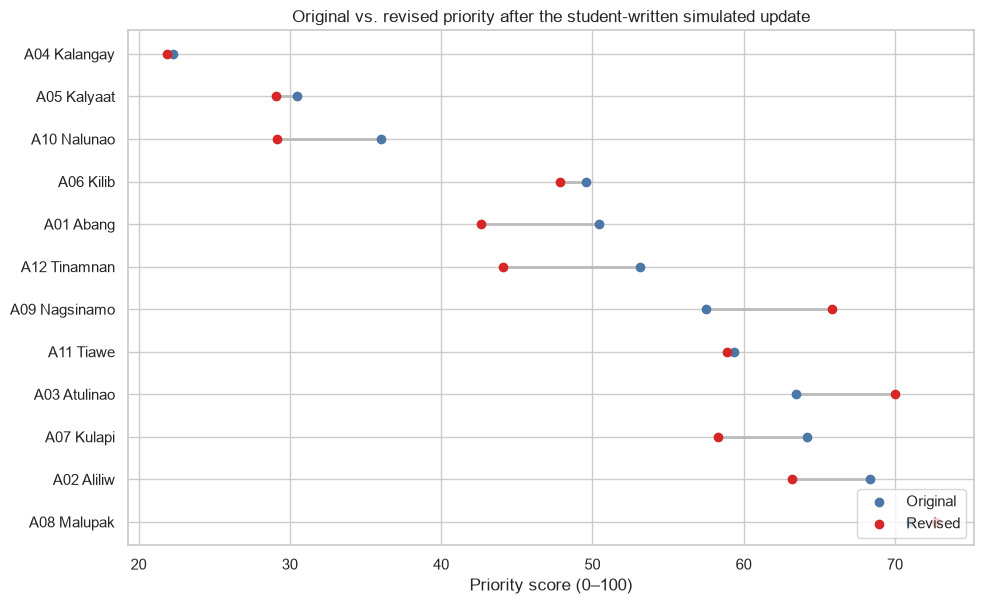

In [11]:
if UPDATE_APPLIED:
    revised_fac = facilities_raw.copy()
    for fid, status in facility_updates.items():
        revised_fac.loc[revised_fac["facility_id"] == fid, "status"] = status
    if new_facilities:
        revised_fac = pd.concat([revised_fac, pd.DataFrame(new_facilities)], ignore_index=True)
    revised_fac["longitude"] = pd.to_numeric(revised_fac["longitude"], errors="coerce")
    revised_fac["latitude"] = pd.to_numeric(revised_fac["latitude"], errors="coerce")
    revised_fac["status"] = revised_fac["status"].str.strip().str.lower()
    revised_fac_gdf = gpd.GeoDataFrame(
        revised_fac,
        geometry=gpd.points_from_xy(revised_fac["longitude"], revised_fac["latitude"]),
        crs=4326,
    ).to_crs(32651)

    revised_operational = revised_fac_gdf[revised_fac_gdf["status"] == "operational"].copy()
    assert len(revised_operational) > 0, "The update leaves no operational facility."

    # zones_proj stays in the original A01-A12 order, while df is sorted by
    # original priority. Attach zone_id from zones_proj before mapping, or the
    # revised distances will be assigned to the wrong zones.
    revised_nearest = zones_proj.apply(
        lambda row: nearest_facility(row, revised_operational), axis=1
    )
    revised_nearest["zone_id"] = zones_proj["zone_id"].values
    assert revised_nearest["zone_id"].is_unique, "Revised nearest table has duplicate zone IDs."
    assert set(revised_nearest["zone_id"]) == set(df["zone_id"]), "Revised nearest table does not cover all zones."
    rev = revised_nearest.set_index("zone_id")
    df["revised_nearest_facility_id"] = df["zone_id"].map(rev["nearest_facility_id"])
    df["revised_nearest_facility_name"] = df["zone_id"].map(rev["nearest_facility_name"])
    df["revised_distance_km"] = df["zone_id"].map(rev["distance_km"])

    # Independent check: each mapped distance must be the minimum distance to an
    # operational facility for that zone's own geometry.
    for _, row in df.iterrows():
        zone_geometry = zones_proj.loc[
            zones_proj["zone_id"] == row["zone_id"], "geometry"
        ].iloc[0]
        manual_distance = (
            revised_operational.geometry.distance(zone_geometry.centroid).min() / 1000.0
        )
        assert np.isclose(row["revised_distance_km"], manual_distance), (
            f"Revised distance mismatch for {row['zone_id']}"
        )

    max_rev_distance = df["revised_distance_km"].max()
    df["revised_distance_score"] = (
        100.0 * df["revised_distance_km"] / max_rev_distance if max_rev_distance > 0 else 0.0
    )
    df["revised_priority"] = (
        0.45 * df["service_gap"]
        + 0.25 * df["risk_score"]
        + 0.20 * df["revised_distance_score"]
        + 0.10 * df["demand_score"]
    )
    revised_ranked = df.sort_values(
        ["revised_priority", "zone_id"], ascending=[False, True]
    ).reset_index(drop=True)
    revised_ranked["revised_rank"] = np.arange(1, len(revised_ranked) + 1)
    rank_map = revised_ranked.set_index("zone_id")["revised_rank"]
    df["revised_rank"] = df["zone_id"].map(rank_map)
    df["facility_changed"] = (
        (df["revised_nearest_facility_id"] != df["original_nearest_facility_id"])
        | (~np.isclose(df["revised_distance_km"], df["original_distance_km"]))
    )
    df["priority_changed"] = (
        (~np.isclose(df["revised_priority"], df["original_priority"]))
        | (df["revised_rank"] != df["original_rank"])
    )
    df["update_affected"] = df["facility_changed"] | df["priority_changed"]
else:
    df["revised_nearest_facility_id"] = df["original_nearest_facility_id"]
    df["revised_nearest_facility_name"] = df["original_nearest_facility_name"]
    df["revised_distance_km"] = df["original_distance_km"]
    df["revised_distance_score"] = df["original_distance_score"]
    df["revised_priority"] = df["original_priority"]
    df["revised_rank"] = df["original_rank"]
    df["facility_changed"] = False
    df["priority_changed"] = False
    df["update_affected"] = False
    revised_fac_gdf = fac_gdf.copy()

df["rank_change"] = df["original_rank"] - df["revised_rank"]  # positive = moved up
df["distance_change_km"] = df["revised_distance_km"] - df["original_distance_km"]
df["final_priority"] = df["revised_priority"]
df["final_rank"] = df["revised_rank"]
final_df = df.sort_values("final_rank").reset_index(drop=True)

df["final_priority"] = df["revised_priority"]
df["final_rank"] = df["revised_rank"]
final_df = df.sort_values("final_rank").reset_index(drop=True)

print("Before/after comparison")
display(
    final_df[
        [
            "zone_id",
            "zone_name",
            "original_priority",
            "original_rank",
            "revised_priority",
            "revised_rank",
            "rank_change",
            "original_distance_km",
            "revised_distance_km",
            "distance_change_km",
            "revised_nearest_facility_id",
            "facility_changed",
            "priority_changed",
            "update_affected",
        ]
    ].round(3)
)

revised_top3 = final_df.head(3)[["zone_id", "zone_name", "revised_priority", "revised_rank"]].copy()
print("Revised top three")
display(revised_top3.round(2))

print("Largest rank changes (positive = moved up)")
display(
    final_df.assign(abs_change=final_df["rank_change"].abs())
    .sort_values(["abs_change", "zone_id"], ascending=[False, True])[
        [
            "zone_id",
            "zone_name",
            "original_rank",
            "revised_rank",
            "rank_change",
            "facility_changed",
            "priority_changed",
        ]
    ]
    .head(6)
)

if UPDATE_APPLIED:
    fig3, ax3 = plt.subplots(figsize=(10, 6.2))
    comp = df.sort_values("original_rank")
    y = np.arange(len(comp))
    ax3.hlines(y, comp["original_priority"], comp["revised_priority"], color="#bbbbbb", linewidth=2)
    ax3.scatter(comp["original_priority"], y, color="#4c78a8", label="Original", zorder=3)
    ax3.scatter(comp["revised_priority"], y, color="#d62728", label="Revised", zorder=3)
    ax3.set_yticks(y)
    ax3.set_yticklabels(comp["zone_id"] + " " + comp["zone_name"])
    ax3.set_xlabel("Priority score (0–100)")
    ax3.set_title("Original vs. revised priority after the student-written simulated update")
    ax3.legend(loc="lower right")
    fig3.tight_layout()
    fig3.savefig(FIG_DIR / "chart3_original_vs_revised.png", dpi=160)
    plt.show()
else:
    print("Before/after chart pending the sealed update.")

### What changed and why

The update changes more than the map label: it changes the operational facility set, the nearest-facility assignment, and the distance normalization. This section records the change in plain language.

In [12]:
if UPDATE_APPLIED:
    status_changes = "; ".join(
        f"{fid} ({facilities_raw.loc[facilities_raw['facility_id'] == fid, 'facility_name'].iloc[0]}) "
        f"to {facility_updates[fid]}"
        for fid in affected_facility_ids
    )
    max_orig = df["original_distance_km"].max()
    max_rev = df["revised_distance_km"].max()
    lead = df.sort_values("original_rank").iloc[0]
    movers = (
        df.assign(abs_change=df["rank_change"].abs())
        .sort_values(["abs_change", "zone_id"], ascending=[False, True])
        .head(4)
    )
    movers_text = "; ".join(
        f"{row.zone_id} {row.zone_name} ({row.original_rank}→{row.revised_rank})"
        for row in movers.itertuples()
    )
    revised_top3_text = "; ".join(
        f"{row.zone_id} {row.zone_name} ({row.revised_priority:.1f})"
        for row in revised_top3.itertuples()
    )
    change_summary = f"""
### What changed and why

**Update provenance.** The applied notice is a **student-written simulated operational update**, not an official LGU release; no written instructor permission is included or claimed. It changes the status of {status_changes}.

**Revised top three.** {revised_top3_text}.

**Distance normalization.** The scenario maximum distance changed from {max_orig:.2f} km to {max_rev:.2f} km. The distance score is relative to that maximum, so a change in the maximum can raise or lower a zone's distance score even when its raw distance is unchanged. For example, {lead['zone_id']} {lead['zone_name']} moved from {lead['original_distance_km']:.2f} km to {lead['revised_distance_km']:.2f} km, while its distance score changed from {lead['original_distance_score']:.1f} to {lead['revised_distance_score']:.1f}.

**Largest rank changes.** {movers_text}. Positive rank change means the zone moved up.

**Interpretation.** The update removes the facility nearest to three catchments. A08, A03, and A09 are reassigned to farther operational facilities, which raises the scenario maximum distance. Zones whose nearest facility is unchanged keep the same raw distance but their normalized distance scores fall, so some lose rank. A08 still ranks first because its new distance is large relative to the new maximum, while A03 and A09 rise because their new distances are even larger. The original top three are preserved for comparison; the revised ranking is a policy-consistent screening result, not a claim about road travel or actual LGU need.
"""
    display(Markdown(change_summary))
else:
    display(Markdown("No operational update has been applied; the revised analysis is pending."))


### What changed and why

**Update provenance.** The applied notice is a **student-written simulated operational update**, not an official LGU release; no written instructor permission is included or claimed. It changes the status of F03 (Scenario Assistance Hub — Nagsinamo) to non-operational.

**Revised top three.** A08 Malupak (72.7); A03 Atulinao (70.0); A09 Nagsinamo (65.8).

**Distance normalization.** The scenario maximum distance changed from 2.36 km to 4.31 km. The distance score is relative to that maximum, so a change in the maximum can raise or lower a zone's distance score even when its raw distance is unchanged. For example, A08 Malupak moved from 1.20 km to 2.55 km, while its distance score changed from 50.6 to 59.1.

**Largest rank changes.** A07 Kulapi (3→6); A09 Nagsinamo (6→3); A02 Aliliw (2→4); A03 Atulinao (4→2). Positive rank change means the zone moved up.

**Interpretation.** The update removes the facility nearest to three catchments. A08, A03, and A09 are reassigned to farther operational facilities, which raises the scenario maximum distance. Zones whose nearest facility is unchanged keep the same raw distance but their normalized distance scores fall, so some lose rank. A08 still ranks first because its new distance is large relative to the new maximum, while A03 and A09 rise because their new distances are even larger. The original top three are preserved for comparison; the revised ranking is a policy-consistent screening result, not a claim about road travel or actual LGU need.


### Revised map

The final HTML uses the revised priority scores, the revised nearest operational facility, and a highlighted marker for the facility whose status changed. The map is explicitly labelled as a student-written simulation, not an official LGU release; no written instructor permission is included or claimed. If no operational update is present, the map remains the original scenario and is labelled as pending.

In [13]:
final_map_data = df.copy()
final_map_data["map_priority"] = final_map_data["final_priority"]
final_map_data["map_rank"] = final_map_data["final_rank"]
final_map_data["map_distance_km"] = final_map_data["revised_distance_km"]
final_map_data["map_distance_score"] = final_map_data["revised_distance_score"]
final_map_data["map_nearest_facility_id"] = final_map_data["revised_nearest_facility_id"]
final_map_data["map_nearest_facility_name"] = final_map_data["revised_nearest_facility_name"]

final_map_path = OUT_DIR / f"CPE15_{STUDENT_ID}_FINAL_MAP.html"
m_final = build_map(
    final_map_data,
    revised_fac_gdf,
    "Final revised scenario — student-written simulated update" if UPDATE_APPLIED else "Original scenario (update pending)",
    affected_facility_ids,
    final_map_path,
)
print(f"Saved final map: {final_map_path}")
m_final

Saved final map: outputs\CPE15_24-001777_FINAL_MAP.html


## 7. Final recommendation

The recommendation is a screening decision under the supplied policy. It is not a claim about actual broadband need, road access, or LGU priorities.

In [14]:
original_top3 = df.sort_values("original_rank").head(3)
revised_top3 = df.sort_values("revised_rank").head(3)

def top3_text(frame, score_col):
    return "; ".join(
        f"{row['zone_id']} {row['zone_name']} ({row[score_col]:.1f})"
        for _, row in frame.iterrows()
    )

if UPDATE_APPLIED:
    status_changes = "; ".join(
        f"{fid} ({facilities_raw.loc[facilities_raw['facility_id'] == fid, 'facility_name'].iloc[0]}) "
        f"to {facility_updates[fid]}"
        for fid in affected_facility_ids
    )
    max_orig = df["original_distance_km"].max()
    max_rev = df["revised_distance_km"].max()
    lead = df.sort_values("original_rank").iloc[0]
    movers = (
        df.assign(abs_change=df["rank_change"].abs())
        .sort_values(["abs_change", "zone_id"], ascending=[False, True])
        .head(4)
    )
    movers_text = "; ".join(
        f"{row.zone_id} {row.zone_name} ({row.original_rank}→{row.revised_rank})"
        for row in movers.itertuples()
    )
    third_fourth_gap = (
        revised_top3.iloc[2]["revised_priority"] - final_df.iloc[3]["revised_priority"]
    )
    update_evidence = (
        "The applied notice is a student-written simulated update, not an official LGU "
        "release; no written instructor permission is included or claimed. It changes the "
        f"status of {status_changes}. "
        "The revised top three are "
        f"{top3_text(revised_top3, 'revised_priority')}. "
        f"The scenario maximum distance changed from {max_orig:.2f} km to {max_rev:.2f} km. "
        "Because distance scores are normalized within the scenario, a zone can move up "
        "even when its raw distance increases. "
        f"For example, {lead['zone_id']} {lead['zone_name']} moved from "
        f"{lead['original_distance_km']:.2f} km to {lead['revised_distance_km']:.2f} km, "
        f"while its distance score changed from {lead['original_distance_score']:.1f} to "
        f"{lead['revised_distance_score']:.1f}. Largest rank changes: {movers_text}. "
        "The original top three are preserved for comparison."
    )
    confidence_note = (
        f"Confidence is moderate: the revised #3 is {third_fourth_gap:.1f} points above #4, "
        "but the result still depends on simulated inputs, straight-line distances, and the "
        "supplied policy weights. The update is a simulation, so this is a method demonstration, "
        "not an official LGU decision."
    )
else:
    update_evidence = (
        "No operational update has been applied in this student-written simulation. The "
        "original ranking is preserved and the revised analysis is pending."
    )
    confidence_note = (
        "Confidence in the original ranking is moderate because A07 and A03 are separated by "
        "less than one priority point, so small corrections can reorder the top three."
    )

recommendation_md = f"""
### Original top three
{top3_text(original_top3, 'original_priority')}

### Revised top three
{top3_text(revised_top3, 'revised_priority') if UPDATE_APPLIED else 'Pending an operational update.'}

### Evidence supporting the change
{update_evidence}

### Limitations and confidence
Distances are straight-line centroid-to-facility measurements in EPSG:32651, not road travel times. The weights are supplied examination policy, not real government policy. All household, risk, request, and facility values are simulated. {confidence_note}
"""
display(Markdown(recommendation_md))


### Original top three
A08 Malupak (71.0); A02 Aliliw (68.4); A07 Kulapi (64.2)

### Revised top three
A08 Malupak (72.7); A03 Atulinao (70.0); A09 Nagsinamo (65.8)

### Evidence supporting the change
The applied notice is a student-written simulated update, not an official LGU release; no written instructor permission is included or claimed. It changes the status of F03 (Scenario Assistance Hub — Nagsinamo) to non-operational. The revised top three are A08 Malupak (72.7); A03 Atulinao (70.0); A09 Nagsinamo (65.8). The scenario maximum distance changed from 2.36 km to 4.31 km. Because distance scores are normalized within the scenario, a zone can move up even when its raw distance increases. For example, A08 Malupak moved from 1.20 km to 2.55 km, while its distance score changed from 50.6 to 59.1. Largest rank changes: A07 Kulapi (3→6); A09 Nagsinamo (6→3); A02 Aliliw (2→4); A03 Atulinao (4→2). The original top three are preserved for comparison.

### Limitations and confidence
Distances are straight-line centroid-to-facility measurements in EPSG:32651, not road travel times. The weights are supplied examination policy, not real government policy. All household, risk, request, and facility values are simulated. Confidence is moderate: the revised #3 is 2.6 points above #4, but the result still depends on simulated inputs, straight-line distances, and the supplied policy weights. The update is a simulation, so this is a method demonstration, not an official LGU decision.


## 8. Exports and validation

The processed CSV contains all twelve zones, the validated inputs, the original and revised scores/ranks, the spatial metrics, and the update flag. The supporting ZIP contains only the HTML map, the CSV, and any required local assets — **not** the six original evidence files.

In [15]:
try:
    from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
    from reportlab.lib.pagesizes import letter
    from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
    from reportlab.lib.units import inch
    from reportlab.platypus import Paragraph, SimpleDocTemplate, Spacer
except ImportError as exc:
    raise ImportError(
        "reportlab is required for the PDF memo. Install it with `pip install reportlab`, "
        "then re-run this export cell."
    ) from exc

csv_columns = [
    "zone_id",
    "zone_name",
    "psgc_code",
    "total_households",
    "households_with_access",
    "service_gap",
    "risk_score",
    "valid_requests",
    "original_nearest_facility_id",
    "original_nearest_facility_name",
    "original_distance_km",
    "original_distance_score",
    "demand_score",
    "original_priority",
    "original_rank",
    "revised_nearest_facility_id",
    "revised_nearest_facility_name",
    "revised_distance_km",
    "revised_distance_score",
    "revised_priority",
    "revised_rank",
    "distance_change_km",
    "facility_changed",
    "priority_changed",
    "update_affected",
    "rank_change",
    "final_priority",
    "final_rank",
    "update_source",
]
df["update_source"] = "student-written simulation" if UPDATE_APPLIED else "none"
csv_path = OUT_DIR / f"CPE15_{STUDENT_ID}_PROCESSED.csv"
df.sort_values("zone_id")[csv_columns].to_csv(csv_path, index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"Saved processed CSV: {csv_path}")

# Decision memo
original_top3 = df.sort_values("original_rank").head(3)
revised_top3 = df.sort_values("revised_rank").head(3)

body_paragraphs = [
    (
        "This memo screens the twelve synthetic 350 m study catchments in Lucban, "
        "Quezon for three hypothetical mobile digital assistance deployments. All "
        "household, risk, request, facility and priority values are simulated teaching "
        "data; the catchments are not official barangay boundaries."
    ),
    (
        "After reconciling the evidence, the original top three are "
        f"{original_top3.iloc[0]['zone_id']} {original_top3.iloc[0]['zone_name']} "
        f"({original_top3.iloc[0]['original_priority']:.1f}), "
        f"{original_top3.iloc[1]['zone_id']} {original_top3.iloc[1]['zone_name']} "
        f"({original_top3.iloc[1]['original_priority']:.1f}), and "
        f"{original_top3.iloc[2]['zone_id']} {original_top3.iloc[2]['zone_name']} "
        f"({original_top3.iloc[2]['original_priority']:.1f}). "
        "The 45% household service-gap component drives the ranking: A08 has the "
        "largest gap (76.9%) and high risk (77); A02 has the highest risk (80) and a "
        "66.0% gap; A07 combines a 63.6% gap with 35 eligible requests. A03 is a close "
        "fourth, so the top-three boundary is sensitive to small corrections."
    ),
]

if UPDATE_APPLIED:
    status_changes = "; ".join(
        f"{fid} ({facilities_raw.loc[facilities_raw['facility_id'] == fid, 'facility_name'].iloc[0]}) "
        f"to {facility_updates[fid]}"
        for fid in affected_facility_ids
    )
    max_orig = df["original_distance_km"].max()
    max_rev = df["revised_distance_km"].max()
    lead = df.sort_values("original_rank").iloc[0]
    third_fourth_gap = (
        revised_top3.iloc[2]["revised_priority"] - final_df.iloc[3]["revised_priority"]
    )
    body_paragraphs.append(
        "The applied notice is a student-written simulated update, not an official LGU "
        "release; no written instructor permission is included or claimed. It changes the "
        f"status of {status_changes}. "
        "Recomputing nearest operational facilities and the "
        "twelve-zone distance normalization produces the revised top three: "
        f"{revised_top3.iloc[0]['zone_id']} {revised_top3.iloc[0]['zone_name']} "
        f"({revised_top3.iloc[0]['revised_priority']:.1f}), "
        f"{revised_top3.iloc[1]['zone_id']} {revised_top3.iloc[1]['zone_name']} "
        f"({revised_top3.iloc[1]['revised_priority']:.1f}), and "
        f"{revised_top3.iloc[2]['zone_id']} {revised_top3.iloc[2]['zone_name']} "
        f"({revised_top3.iloc[2]['revised_priority']:.1f}). "
        f"The scenario maximum distance rises from {max_orig:.2f} km to {max_rev:.2f} km, "
        f"so {lead['zone_id']}'s raw distance increases from "
        f"{lead['original_distance_km']:.2f} to {lead['revised_distance_km']:.2f} km "
        "while its distance score rises; A02 and A07 keep their raw distances but lose "
        "relative score. A02 falls to fourth and A07 to sixth. The original top three "
        "are preserved for comparison."
    )
else:
    body_paragraphs.append(
        "No operational update has been applied in this student-written simulation. The revised "
        "top three, the affected facility, and the recomputed distance normalization "
        "remain pending."
    )

if UPDATE_APPLIED:
    limitations_text = (
        "Limitations: distances are straight-line centroid-to-facility measurements, not "
        "road travel times; the weights are supplied examination policy, not real government "
        "policy; and all statistics are fictional. "
        f"Confidence is moderate: the revised #3 is {third_fourth_gap:.1f} points above #4, "
        "but the ranking still depends on simulated inputs and the scenario normalization. "
        "The update is a simulation, so this is a transparent screening exercise, not an "
        "official LGU needs assessment."
    )
else:
    limitations_text = (
        "Limitations: distances are straight-line centroid-to-facility measurements, not "
        "road travel times; the weights are supplied examination policy, not real government "
        "policy; and all statistics are fictional. Confidence in the original ranking is "
        "moderate because several zones are close in score. This is a transparent screening "
        "exercise, not an operational needs assessment."
    )
body_paragraphs.append(limitations_text)

body_text = " ".join(body_paragraphs)
word_count = len(re.findall(r"\b\w+\b", body_text))
print(f"Memo body word count: {word_count}")
assert word_count <= 350, "Decision memo body exceeds 350 words."

pdf_path = OUT_DIR / f"CPE15_{STUDENT_ID}_DECISION.pdf"


def pdf_safe(text: object) -> str:
    """Replace characters the built-in PDF fonts cannot render."""
    return (
        str(text)
        .replace("\u2014", "-")
        .replace("\u2013", "-")
        .replace("\u2018", "'")
        .replace("\u2019", "'")
        .replace("\u201c", '"')
        .replace("\u201d", '"')
        .replace("\u2026", "...")
        .replace("\u2192", "->")
    )


styles = getSampleStyleSheet()
styles.add(
    ParagraphStyle(
        name="MemoTitle",
        parent=styles["Title"],
        fontName="Helvetica-Bold",
        fontSize=13,
        leading=16,
        alignment=TA_CENTER,
        spaceAfter=4,
    )
)
styles.add(
    ParagraphStyle(
        name="MemoMeta",
        parent=styles["Normal"],
        fontName="Helvetica",
        fontSize=9,
        leading=12,
        alignment=TA_CENTER,
        textColor="#333333",
        spaceAfter=10,
    )
)
styles.add(
    ParagraphStyle(
        name="MemoBody",
        parent=styles["BodyText"],
        fontName="Helvetica",
        fontSize=9.6,
        leading=12.6,
        alignment=TA_JUSTIFY,
        spaceAfter=6,
    )
)

tmp_pdf_path = pdf_path.with_name(pdf_path.stem + ".tmp.pdf")
doc = SimpleDocTemplate(
    str(tmp_pdf_path),
    pagesize=letter,
    leftMargin=0.9 * inch,
    rightMargin=0.9 * inch,
    topMargin=0.8 * inch,
    bottomMargin=0.8 * inch,
    title=pdf_safe(f"CPE15 Decision Memo - {STUDENT_ID}"),
    author=pdf_safe(STUDENT_NAME),
)
story = [
    Paragraph(pdf_safe("CPE15 Decision Memo: Operation Blank Map"), styles["MemoTitle"]),
    Paragraph(
        pdf_safe(
            f"{STUDENT_NAME} &nbsp;|&nbsp; Student ID {STUDENT_ID} &nbsp;|&nbsp; "
            f"Section {SECTION} &nbsp;|&nbsp; {COURSE} &nbsp;|&nbsp; {MEMO_DATE}"
        ),
        styles["MemoMeta"],
    ),
]
for paragraph in body_paragraphs:
    story.append(Paragraph(pdf_safe(paragraph), styles["MemoBody"]))
story.append(Spacer(1, 8))
story.append(
    Paragraph(
        pdf_safe(
            f"<i>Memo body word count: {word_count} (limit 350, excluding identification heading).</i>"
        ),
        styles["MemoMeta"],
    )
)
doc.build(story)
try:
    tmp_pdf_path.replace(pdf_path)
    print(f"Saved decision memo: {pdf_path}")
except PermissionError:
    print(
        f"WARNING: {pdf_path.name} is open in another program. "
        f"The new memo was written to {tmp_pdf_path.name}; close the PDF viewer "
        "and replace the old file before submitting."
    )

# Supporting ZIP
zip_path = OUT_DIR / f"CPE15_{STUDENT_ID}_SUPPORTING.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(final_map_path, arcname=final_map_path.name)
    archive.write(csv_path, arcname=csv_path.name)
print(f"Saved supporting ZIP: {zip_path}")

# Validation
print("\nFinal validation")
checks = {
    "12 zones in integrated table": len(df) == 12 and df["zone_id"].is_unique,
    "No missing critical inputs": df[
        ["total_households", "households_with_access", "risk_score", "valid_requests"]
    ].notna().all().all(),
    "Access never exceeds total households": (
        df["households_with_access"] <= df["total_households"]
    ).all(),
    "Distance CRS is projected (EPSG:32651)": str(zones_proj.crs).endswith("32651"),
    "Processed CSV exists": csv_path.exists(),
    "Final HTML map exists": final_map_path.exists(),
    "Decision PDF exists": pdf_path.exists(),
    "Supporting ZIP exists": zip_path.exists(),
    "Memo body <= 350 words": word_count <= 350,
    "Update parsed as applied": UPDATE_APPLIED,
    "At least one zone directly affected": bool(df["facility_changed"].any()),
    "Revised priorities differ from original": not np.allclose(
        df["revised_priority"], df["original_priority"]
    ),
    "Rank changes recorded": "rank_change" in df.columns,
    "Update source recorded": "update_source" in df.columns,
    "Correction residual uncertainty populated": bool(
        correction_log["residual_uncertainty"].notna().all()
        and (correction_log["residual_uncertainty"].astype(str).str.strip() != "").all()
    ),
}
checks["A07 duplicate rows verified identical"] = a07_duplicate_verified
for label, passed in checks.items():
    print(f"  [{'PASS' if passed else 'FAIL'}] {label}")

with zipfile.ZipFile(zip_path) as archive:
    names = archive.namelist()
print("  ZIP contents:", names)
assert final_map_path.name in names
assert csv_path.name in names
assert not any(name in names for name in ORIGINAL_EVIDENCE_FILES), "Original evidence file found in ZIP."
print("  [PASS] ZIP excludes the six original evidence files")

final_html = final_map_path.read_text(encoding="utf-8")
html_checks = {
    "Final map does not say 'sealed update pending'": "sealed update pending" not in final_html.lower(),
    "Final map has affected-facility layer": "Facility status changed by update" in final_html,
    "Final map discloses student-written simulation": "student-written simulation" in final_html.lower(),
    "Final map does not claim instructor authorization": "authorized by the instructor" not in final_html.lower(),
}
for label, passed in html_checks.items():
    print(f"  [{'PASS' if passed else 'FAIL'}] {label}")

csv_header = csv_path.read_text(encoding="utf-8").splitlines()[0]
csv_checks = {
    "CSV contains rank_change": "rank_change" in csv_header,
    "CSV contains update_source": "update_source" in csv_header,
    "CSV contains revised_priority": "revised_priority" in csv_header,
}
for label, passed in csv_checks.items():
    print(f"  [{'PASS' if passed else 'FAIL'}] {label}")

print("  [PASS] Operational update applied" if UPDATE_APPLIED else "  [PENDING] Operational update and revised ranking")

Saved processed CSV: outputs\CPE15_24-001777_PROCESSED.csv
Memo body word count: 308
Saved decision memo: outputs\CPE15_24-001777_DECISION.pdf


Saved supporting ZIP: outputs\CPE15_24-001777_SUPPORTING.zip

Final validation
  [PASS] 12 zones in integrated table
  [PASS] No missing critical inputs
  [PASS] Access never exceeds total households
  [PASS] Distance CRS is projected (EPSG:32651)
  [PASS] Processed CSV exists
  [PASS] Final HTML map exists
  [PASS] Decision PDF exists
  [PASS] Supporting ZIP exists
  [PASS] Memo body <= 350 words
  [PASS] Update parsed as applied
  [PASS] At least one zone directly affected
  [PASS] Revised priorities differ from original
  [PASS] Rank changes recorded
  [PASS] Update source recorded
  [PASS] Correction residual uncertainty populated
  [PASS] A07 duplicate rows verified identical
  ZIP contents: ['CPE15_24-001777_FINAL_MAP.html', 'CPE15_24-001777_PROCESSED.csv']
  [PASS] ZIP excludes the six original evidence files
  [PASS] Final map does not say 'sealed update pending'
  [PASS] Final map has affected-facility layer
  [PASS] Final map discloses student-written simulation
  [PASS] Fina